# 🚚 Olist Delivery Delay Prediction - End to End ML Project
**Problem:** Order place hote hi predict karo ki wo estimated date tak deliver hoga ya **late** hoga, aur delivery kitne din me hogi.

**Models:** Logistic Regression, Decision Tree, Random Forest (classification) | Linear Regression, Decision Tree, Random Forest (regression) | KMeans (segmentation)

**Pipeline:** Load → Merge → EDA → Preprocessing → Models (Train vs Test) → Evaluation → Business Impact → Conclusion
## 1. Libraries Import

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns 
import joblib 
import warnings
warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression,LinearRegression
from sklearn.tree import DecisionTreeClassifier,DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier,RandomForestRegressor
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score,precision_score,recall_score,f1_score,r2_score,mean_absolute_error,confusion_matrix,roc_curve)

## 2. Data Load

In [2]:
orders = pd.read_csv("olist_orders_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
products = pd.read_csv("olist_products_Dataset.csv")
translation = pd.read_csv("Product_category_name_translation.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")

In [3]:
# CSV files same folder me hain to path khali rehne do

orders = pd.read_csv("olist_orders_dataset.csv")
items = pd.read_csv("olist_order_items_dataset.csv")
customers = pd.read_csv("olist_customers_dataset.csv")
sellers = pd.read_csv("olist_sellers_dataset.csv")
products = pd.read_csv("olist_products_dataset.csv")
translation = pd.read_csv("product_category_name_translation.csv")
geo = pd.read_csv("olist_geolocation_dataset.csv")

orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


In [4]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date'],
      dtype='str')

In [5]:
orders.shape

(99441, 8)

In [6]:
orders.isnull().sum()

order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

In [7]:
orders.duplicated().sum()

np.int64(0)

## 3. Cleaning - Orders
Sirf **delivered** orders lo, aur 2 targets banao:
- `is_late` → 1 agar estimated date ke baad aaya, warna 0 (classification)
- `delivery_days` → kitne din lage (regression)

In [8]:
df = orders[orders["order_status"] == "delivered"].copy()
df = df.dropna(subset=["order_delivered_customer_date"])

# date wale columns ko date type me badlo
for col in ["order_purchase_timestamp", "order_delivered_customer_date", "order_estimated_delivery_date"]:
    df[col] = pd.to_datetime(df[col])

df["is_late"] = (df["order_delivered_customer_date"] > df["order_estimated_delivery_date"]).astype(int)
df["delivery_days"] = (df["order_delivered_customer_date"] - df["order_purchase_timestamp"]).dt.days

df[["order_id", "is_late", "delivery_days"]].head()

,order_id,is_late,delivery_days
0,e481f51cbdc54678b7cc49136f2d6af7,0,8
1,53cdb2fc8bc7dce0b6741e2150273451,0,13
2,47770eb9100c2d0c44946d9cf07ec65d,0,9
3,949d5b44dbf5de918fe9c16f97b45f8a,0,13
4,ad21c59c0840e6cb83a9ceb5573f8159,0,2


## 4. Cleaning - Items, Products, Geolocation
Ek order me kai items ho sakte hain, isliye `order_id` ke hisaab se group karte hain.

In [9]:
# Items: har order ki ek row
items_grouped = items.groupby("order_id").agg({
    "price": "sum",
    "freight_value": "sum",
    "order_item_id": "count",
    "seller_id": "first",
    "product_id": "first"
}).reset_index()
items_grouped = items_grouped.rename(columns={"freight_value": "freight", "order_item_id": "total_items"})

# Products: english category + volume
products = products.merge(translation, on="product_category_name", how="left")
products["volume_cm3"] = products["product_length_cm"] * products["product_height_cm"] * products["product_width_cm"]
products = products.rename(columns={"product_category_name_english": "category"})
products = products[["product_id", "category", "product_weight_g", "volume_cm3"]]

# Geo: ek zip code ke kai lat/lng hain, to average le lo
geo_avg = geo.groupby("geolocation_zip_code_prefix")[["geolocation_lat", "geolocation_lng"]].mean().reset_index()
geo_avg.head()

,geolocation_zip_code_prefix,geolocation_lat,geolocation_lng
0,1001,-23.550190,-46.634024
1,1002,-23.548146,-46.634979
2,1003,-23.548994,-46.635731
3,1004,-23.549799,-46.634757
4,1005,-23.549456,-46.636733


## 5. Saari Tables Merge
Customer aur seller dono ka lat/lng chahiye, isliye geo table 2 baar alag naam se lagayenge.

In [10]:
# Customer ka location
cust_geo = geo_avg.rename(columns={'geolocation_zip_code_prefix': 'customer_zip_code_prefix','geolocation_lat':'cust_lat','geolocation_lng':'cust_lng'})

# Seller ka location
sell_geo = geo_avg.rename(columns={'geolocation_zip_code_prefix': 'seller_zip_code_prefix','geolocation_lat': 'sell_lat', 'geolocation_lng':'sell_lng'})

# Extra columns hatao (cell dobara run kar sako)
df = df[list(orders.columns) + ['is_late', 'delivery_days']]

# Customer zip aur state
df = df.merge(customers[['customer_id','customer_zip_code_prefix','customer_state']],on='customer_id',how= 'left')
# Price, freight, items
df = df.merge(items_grouped, on = 'order_id',how='inner')
# Category, weight, volume
df = df.merge(products, on= 'product_id', how = 'left')
# Seller zip aur state
df = df.merge(sellers[['seller_id','seller_zip_code_prefix','seller_state']], on = 'seller_id',how = 'left')
# Customer lat/lng
df = df.merge(cust_geo,on='customer_zip_code_prefix',how='left')
# Seller lat/lng
df = df.merge(sell_geo,on='seller_zip_code_prefix',how='left')

print(df.shape)

(96470, 26)


## 6. Feature Engineering
Sirf wo features jo **order place hote waqt** pata hote hain (delivery ke baad wali cheez use nahi karni, warna data leakage).

In [11]:
df = df.dropna(subset=['cust_lat','cust_lng','sell_lat','sell_lng']).copy()   # lat/lng khali wali rows hatao

lat_diff = df['cust_lat'] - df['sell_lat']                      # latitude ka fark
lng_diff = df['cust_lng'] - df['sell_lng']                      # longitude ka fark
df['distance_km'] = np.sqrt(lat_diff ** 2 + lng_diff ** 2) * 111   # seedhi doori, 1 degree = lagbhag 111 km

df['same_state'] = (df['customer_state'] == df['seller_state']).astype(int)   # same state = 1, alag = 0

df['purchase_month'] = df['order_purchase_timestamp'].dt.month        # order kis mahine me hua
df['purchase_dayofweek'] = df['order_purchase_timestamp'].dt.dayofweek   # kaunse din (0 = Monday)
df['purchase_hour'] = df['order_purchase_timestamp'].dt.hour          # din ke kaunse ghante me

df['estimated_days'] = (df['order_estimated_delivery_date'] - df['order_purchase_timestamp']).dt.days   # company ne kitne din bole the

df['product_weight_g'] = df['product_weight_g'].fillna(df['product_weight_g'].median())   # khali weight = median
df['volume_cm3'] = df['volume_cm3'].fillna(df['volume_cm3'].median())                     # khali volume = median
df['category'] = df['category'].fillna('unknown')                                         # khali category = unknown

top_cat = df['category'].value_counts().head(10).index                        # sabse zyada wali 10 categories
df['category'] = df['category'].where(df['category'].isin(top_cat), 'other')  # baaki sab 'other'

df = df[df['delivery_days'] <= 60]                                     # 60 din se zyada wali extreme deliveries hatao

df = df.sort_values('order_purchase_timestamp').reset_index(drop=True)   # purane order pehle, naye baad me

print('Final shape :', df.shape)                                       # rows aur columns
print('Late orders %', round(df['is_late'].mean() * 100, 2))           # kitne % order late hue
df[['distance_km','price','freight','estimated_days','delivery_days','is_late']].describe().round(2)   # in columns ka summary

Final shape : (95707, 32)
Late orders % 7.83


,distance_km,price,freight,estimated_days,delivery_days,is_late
count,95707.00,95707.00,95707.00,95707.00,95707.00,95707.00
mean,617.55,136.94,22.76,23.35,11.86,0.08
std,598.27,209.13,21.55,8.75,8.40,0.27
min,0.00,0.85,0.00,2.00,0.00,0.00
25%,192.18,45.90,13.82,18.00,6.00,0.00
50%,452.48,86.00,17.16,23.00,10.00,0.00
75%,823.35,149.90,23.98,28.00,15.00,0.00
max,8835.70,13440.00,1794.96,155.00,60.00,1.00


## 7. EDA - Graphs

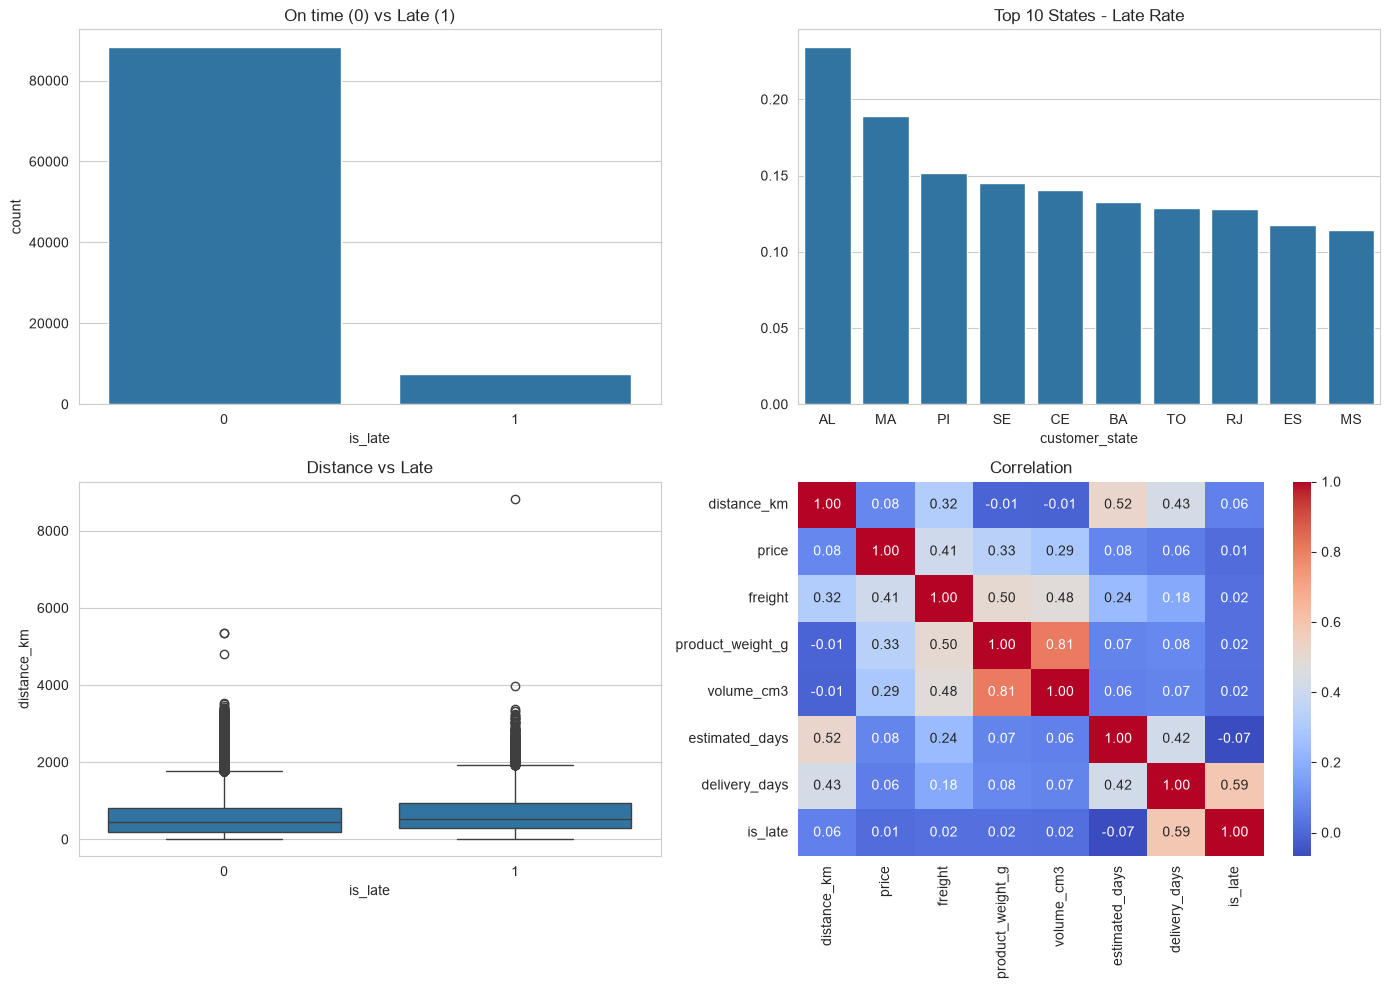

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# 1. Late vs On-time
sns.countplot(x="is_late", data=df, ax=axes[0, 0])
axes[0, 0].set_title("On time (0) vs Late (1)")

# 2. Top 10 states jaha late zyada hota hai
state_late = df.groupby("customer_state")["is_late"].mean().sort_values(ascending=False).head(10)
sns.barplot(x=state_late.index, y=state_late.values, ax=axes[0, 1])
axes[0, 1].set_title("Top 10 States - Late Rate")

# 3. Distance vs late
sns.boxplot(x="is_late", y="distance_km", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Distance vs Late")

# 4. Correlation heatmap
corr_cols = ["distance_km", "price", "freight", "product_weight_g", "volume_cm3", "estimated_days", "delivery_days", "is_late"]
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1, 1])
axes[1, 1].set_title("Correlation")

plt.tight_layout()
plt.show()

## 8. Preprocessing - Encoding, Split, Scaling
- **One-Hot Encoding:** text columns (state, category) ko 0/1 columns me badla
- **Time-based split:** purane 80% orders = train, naye 20% = test
- **Scaling:** train pe `fit`, test pe sirf `transform`

In [ ]:
from sklearn.model_selection import train_test_split 

num_cols = ['distance_km','price','seller_state','category']

X = pd.get_dummies(df[num_cols + cat_  ])

In [13]:
from sklearn.model_selection import train_test_split   # split karne wala function

num_cols = ["distance_km", "price", "freight", "total_items", "product_weight_g", "volume_cm3",
            "purchase_month", "purchase_dayofweek", "purchase_hour", "estimated_days", "same_state"]   # number wali columns
cat_cols = ["customer_state", "seller_state", "category"]   # text wali columns

X = pd.get_dummies(df[num_cols + cat_cols], columns=cat_cols, drop_first=True).astype(float)   # text ko 0/1 columns me badlo
y = df["is_late"]            # late hoga ya nahi (classification ka answer)
y_reg = df["delivery_days"]  # kitne din lagenge (regression ka answer)

# 80% train, 20% test. shuffle=False = purane orders train me, naye test me
X_train, X_test, y_train, y_test, yr_train, yr_test = train_test_split(
    X, y, y_reg, test_size=0.2, shuffle=False)

scaler = StandardScaler()                       # sab columns ko same scale pe lane wala
X_train_s = scaler.fit_transform(X_train)       # train se seekho aur scale karo
X_test_s = scaler.transform(X_test)             # test ko sirf scale karo (seekhna nahi)

print("Train:", X_train_s.shape, "| Test:", X_test_s.shape)   # train aur test ki rows, columns

Train: (76565, 68) | Test: (19142, 68)
